In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Detect project root.
# This works both if the notebook is opened from the repo root
# and if it is opened from the notebooks/ folder.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT exists:", PROJECT_ROOT.exists())
print("configs/req1.yaml exists:", (PROJECT_ROOT / "configs" / "req1.yaml").exists())
print("experiments/run_req1.py exists:", (PROJECT_ROOT / "experiments" / "run_req1.py").exists())
print("ola package exists:", (PROJECT_ROOT / "ola").exists())

PROJECT_ROOT: /Users/foadzahedilabaf/Projects/ola-project
PROJECT_ROOT exists: True
configs/req1.yaml exists: True
experiments/run_req1.py exists: True
ola package exists: True


In [2]:
from ola.environments.single_campaign import SingleCampaignEnvironment
from ola.algorithms.ucb1 import UCB1
from ola.algorithms.budgeted_ucb import BudgetedUCB

from experiments.run_req1 import (
    load_req1_config,
    compute_req1_benchmarks,
    run_algorithm,
    save_algorithm_results,
)

print("All Req 1 project imports worked correctly.")

All Req 1 project imports worked correctly.


In [3]:
config_path = PROJECT_ROOT / "configs" / "req1.yaml"

config = load_req1_config(config_path)

print("Loaded config from:", config_path)
print("Top-level config keys:")
for key in config.keys():
    print("-", key)

print("\nFull config:")
config

Loaded config from: /Users/foadzahedilabaf/Projects/ola-project/configs/req1.yaml
Top-level config keys:
- experiment
- campaign
- bids
- environment
- outputs

Full config:


{'experiment': {'name': 'req1_single_campaign',
  'random_seed': 42,
  'horizon': 1000},
 'campaign': {'value': 1.0, 'initial_budget': 300.0},
 'bids': {'values': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]},
 'environment': {'competing_bid_distribution': 'uniform',
  'min_competing_bid': 0.0,
  'max_competing_bid': 1.0},
 'outputs': {'results_dir': 'results/raw',
  'ucb1_results_file': 'results/raw/req1_ucb1.csv',
  'budgeted_ucb_results_file': 'results/raw/req1_budgeted_ucb.csv'}}

In [4]:
experiment_config = config["experiment"]
campaign_config = config["campaign"]
bids_config = config["bids"]
environment_config = config["environment"]
outputs_config = config["outputs"]

experiment_name = experiment_config["name"]
random_seed = int(experiment_config["random_seed"])
horizon = int(experiment_config["horizon"])

value = float(campaign_config["value"])
initial_budget = float(campaign_config["initial_budget"])
rho = initial_budget / horizon

bids = np.array(bids_config["values"], dtype=float)

competing_bid_distribution = environment_config["competing_bid_distribution"]
min_competing_bid = float(environment_config["min_competing_bid"])
max_competing_bid = float(environment_config["max_competing_bid"])

print("Experiment name:", experiment_name)
print("Random seed:", random_seed)
print("Horizon T:", horizon)
print("Campaign value v:", value)
print("Initial budget B:", initial_budget)
print("Per-round budget rho = B/T:", rho)
print("Bid set:", bids)
print("Number of bids:", len(bids))
print("Competing bid distribution:", competing_bid_distribution)
print("Competing bid support:", [min_competing_bid, max_competing_bid])

print("\nSanity checks:")
print("T > 0:", horizon > 0)
print("0 <= value <= 1:", 0 <= value <= 1)
print("0 <= initial_budget <= T:", 0 <= initial_budget <= horizon)
print("0 <= rho <= 1:", 0 <= rho <= 1)
print("All bids in [0, 1]:", np.all((bids >= 0) & (bids <= 1)))
print("Bids sorted increasingly:", np.all(np.diff(bids) >= 0))
print("Uniform support valid:", 0 <= min_competing_bid < max_competing_bid <= 1)

Experiment name: req1_single_campaign
Random seed: 42
Horizon T: 1000
Campaign value v: 1.0
Initial budget B: 300.0
Per-round budget rho = B/T: 0.3
Bid set: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
Number of bids: 11
Competing bid distribution: uniform
Competing bid support: [0.0, 1.0]

Sanity checks:
T > 0: True
0 <= value <= 1: True
0 <= initial_budget <= T: True
0 <= rho <= 1: True
All bids in [0, 1]: True
Bids sorted increasingly: True
Uniform support valid: True


In [5]:
def expected_win_probability_uniform(bid, min_bid, max_bid):
    """P(m <= bid) when m ~ Uniform(min_bid, max_bid)."""
    if bid <= min_bid:
        return 0.0 if bid < min_bid else 0.0
    if bid >= max_bid:
        return 1.0
    return (bid - min_bid) / (max_bid - min_bid)


rows = []

for bid in bids:
    win_probability = expected_win_probability_uniform(
        bid=bid,
        min_bid=min_competing_bid,
        max_bid=max_competing_bid,
    )

    expected_reward = (value - bid) * win_probability
    expected_cost = bid * win_probability

    rows.append(
        {
            "bid": bid,
            "win_probability": win_probability,
            "expected_reward": expected_reward,
            "expected_cost": expected_cost,
            "budget_feasible_alone": expected_cost <= rho,
        }
    )

bid_table = pd.DataFrame(rows)

bid_table

,bid,win_probability,expected_reward,expected_cost,budget_feasible_alone
0,0.0,0.0,0.00,0.00,True
1,0.1,0.1,0.09,0.01,True
2,0.2,0.2,0.16,0.04,True
3,0.3,0.3,0.21,0.09,True
4,0.4,0.4,0.24,0.16,True
5,0.5,0.5,0.25,0.25,True
6,0.6,0.6,0.24,0.36,False
7,0.7,0.7,0.21,0.49,False
8,0.8,0.8,0.16,0.64,False
9,0.9,0.9,0.09,0.81,False


In [6]:
reward_only_best_row = bid_table.loc[bid_table["expected_reward"].idxmax()]

feasible_bid_table = bid_table[bid_table["budget_feasible_alone"]]
best_feasible_single_bid_row = feasible_bid_table.loc[
    feasible_bid_table["expected_reward"].idxmax()
]

print("Reward-only best bid")
print("--------------------")
print("bid:", reward_only_best_row["bid"])
print("expected reward:", reward_only_best_row["expected_reward"])
print("expected cost:", reward_only_best_row["expected_cost"])

print("\nBest feasible single bid under rho")
print("----------------------------------")
print("bid:", best_feasible_single_bid_row["bid"])
print("expected reward:", best_feasible_single_bid_row["expected_reward"])
print("expected cost:", best_feasible_single_bid_row["expected_cost"])
print("rho:", rho)

Reward-only best bid
--------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25

Best feasible single bid under rho
----------------------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25
rho: 0.3


In [7]:
env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

initial_state = env.reset()

print("Initial state:")
print(initial_state)

Initial state:
{'round': 0, 'budget_left': 300.0, 'done': False, 'info': {'value': 1.0, 'horizon': 1000, 'min_competing_bid': 0.0, 'max_competing_bid': 1.0}}


In [8]:
test_env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=10,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

test_env.reset()

test_bids = [0.0, 0.2, 0.5, 0.8, 1.0]
test_rows = []

for bid in test_bids:
    outcome = test_env.step(bid)

    highest_competing_bid = outcome["info"]["highest_competing_bid"]
    win = outcome["wins"]
    reward = outcome["reward"]
    cost = outcome["cost"]

    manually_expected_win = int(bid >= highest_competing_bid)
    manually_expected_reward = float(value - bid) if manually_expected_win else 0.0
    manually_expected_cost = float(bid) if manually_expected_win else 0.0

    test_rows.append(
        {
            "round": outcome["round"],
            "bid": bid,
            "highest_competing_bid": highest_competing_bid,
            "win": win,
            "reward": reward,
            "cost": cost,
            "budget_left": outcome["budget_left"],
            "manual_win_check": win == manually_expected_win,
            "manual_reward_check": np.isclose(reward, manually_expected_reward),
            "manual_cost_check": np.isclose(cost, manually_expected_cost),
        }
    )

step_check_table = pd.DataFrame(test_rows)
step_check_table

,round,bid,highest_competing_bid,win,reward,cost,budget_left,manual_win_check,manual_reward_check,manual_cost_check
0,1,0.0,0.773956,0,0.0,0.0,300.0,True,True,True
1,2,0.2,0.438878,0,0.0,0.0,300.0,True,True,True
2,3,0.5,0.858598,0,0.0,0.0,300.0,True,True,True
3,4,0.8,0.697368,1,0.2,0.8,299.2,True,True,True
4,5,1.0,0.094177,1,0.0,1.0,298.2,True,True,True


In [9]:
ucb1_benchmark, budgeted_ucb_benchmark = compute_req1_benchmarks(
    bids=bids,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
)

print("Official UCB1 benchmark per round:", ucb1_benchmark)
print("Official Budgeted UCB benchmark per round:", budgeted_ucb_benchmark)

print("\nManual reward-only best expected reward:", reward_only_best_row["expected_reward"])
print("Manual best feasible single-bid expected reward:", best_feasible_single_bid_row["expected_reward"])

Official UCB1 benchmark per round: 0.25
Official Budgeted UCB benchmark per round: 0.25

Manual reward-only best expected reward: 0.25
Manual best feasible single-bid expected reward: 0.25


In [10]:
ucb1_debug = UCB1(actions=bids, horizon=horizon)

ucb1_debug_rows = []

# UCB1 should first try every bid once.
for step in range(len(bids)):
    selected_action = ucb1_debug.select_action()

    # Give a fake reward only to test whether counts and updates work.
    fake_reward = 1.0 - selected_action

    ucb1_debug.update(action=selected_action, reward=fake_reward)

    ucb1_debug_rows.append(
        {
            "step": step + 1,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "counts_after_update": ucb1_debug.counts.copy(),
            "total_rewards_after_update": ucb1_debug.total_rewards.copy(),
        }
    )

ucb1_debug_table = pd.DataFrame(ucb1_debug_rows)

print("Final counts after initial exploration:")
print(ucb1_debug.counts)

ucb1_debug_table[["step", "selected_action", "fake_reward"]]

Final counts after initial exploration:
[1 1 1 1 1 1 1 1 1 1 1]


,step,selected_action,fake_reward
0,1,0.0,1.0
1,2,0.1,0.9
2,3,0.2,0.8
3,4,0.3,0.7
4,5,0.4,0.6
5,6,0.5,0.5
6,7,0.6,0.4
7,8,0.7,0.3
8,9,0.8,0.2
9,10,0.9,0.1


In [11]:
budgeted_ucb_debug = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_debug_rows = []

# Test one update for each bid, using fake reward and fake cost.
# This checks that BudgetedUCB updates both reward and cost estimates.
for step, selected_action in enumerate(bids, start=1):
    fake_reward = 1.0 - selected_action
    fake_cost = selected_action

    budgeted_ucb_debug.update(
        action=selected_action,
        reward=fake_reward,
        cost=fake_cost,
    )

    budgeted_ucb_debug_rows.append(
        {
            "step": step,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "fake_cost": fake_cost,
        }
    )

budgeted_ucb_debug_table = pd.DataFrame(budgeted_ucb_debug_rows)

print("Counts after one fake update per bid:")
print(budgeted_ucb_debug.counts)

print("\nTotal rewards after fake updates:")
print(budgeted_ucb_debug.total_rewards)

print("\nTotal costs after fake updates:")
print(budgeted_ucb_debug.total_costs)

print("\nBudget left after fake updates:")
print(budgeted_ucb_debug.budget_left)

budgeted_ucb_debug_table

Counts after one fake update per bid:
[1 1 1 1 1 1 1 1 1 1 1]

Total rewards after fake updates:
[1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0.2 0.1 0. ]

Total costs after fake updates:
[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]

Budget left after fake updates:
294.5


,step,selected_action,fake_reward,fake_cost
0,1,0.0,1.0,0.0
1,2,0.1,0.9,0.1
2,3,0.2,0.8,0.2
3,4,0.3,0.7,0.3
4,5,0.4,0.6,0.4
5,6,0.5,0.5,0.5
6,7,0.6,0.4,0.6
7,8,0.7,0.3,0.7
8,9,0.8,0.2,0.8
9,10,0.9,0.1,0.9


In [12]:
ucb1 = UCB1(actions=bids, horizon=horizon)

ucb1_rows = run_algorithm(
    algorithm_name="ucb1",
    learner=ucb1,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=ucb1_benchmark,
)

ucb1_df = pd.DataFrame(ucb1_rows)

print("Number of rows:", len(ucb1_df))
print("First rows:")
display(ucb1_df.head())

print("\nLast rows:")
display(ucb1_df.tail())

Number of rows: 1000
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
995,ucb1,996,0.8,0.8,0,0.0,0.0,1.665335e-16,178.0,300.0,0.25,0.25,71.00,0.437990,False,1.665335e-16
996,ucb1,997,0.4,0.4,0,0.0,0.0,1.665335e-16,178.0,300.0,0.25,0.25,71.25,0.639014,False,1.665335e-16
997,ucb1,998,0.2,0.2,0,0.0,0.0,1.665335e-16,178.0,300.0,0.25,0.25,71.50,0.002309,False,1.665335e-16
998,ucb1,999,0.3,0.3,0,0.0,0.0,1.665335e-16,178.0,300.0,0.25,0.25,71.75,0.993368,False,1.665335e-16
999,ucb1,1000,0.7,0.7,0,0.0,0.0,1.665335e-16,178.0,300.0,0.25,0.25,72.00,0.280896,True,1.665335e-16


In [13]:
required_columns = [
    "algorithm",
    "round",
    "action",
    "bids",
    "wins",
    "reward",
    "cost",
    "budget_left",
    "cumulative_reward",
    "cumulative_cost",
    "benchmark_reward",
    "instant_regret",
    "cumulative_regret",
]

missing_columns = [col for col in required_columns if col not in ucb1_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(ucb1_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(ucb1_df["round"].min()))
print("last round:", int(ucb1_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(ucb1_df["budget_left"].min()))
print("final budget_left:", float(ucb1_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(ucb1_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((ucb1_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(ucb1_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(ucb1_df["done"].iloc[-1]))
print("stopped early:", len(ucb1_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['ucb1']
Length: 1, dtype: str

Round range:
first round: 1
last round: 1000

Budget checks:
minimum budget_left: 1.6653345369377348e-16
final budget_left: 1.6653345369377348e-16
final cumulative_cost: 300.00000000000034
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: False


In [14]:
budgeted_ucb = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_rows = run_algorithm(
    algorithm_name="budgeted_ucb",
    learner=budgeted_ucb,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=budgeted_ucb_benchmark,
)

budgeted_ucb_df = pd.DataFrame(budgeted_ucb_rows)

print("Number of rows:", len(budgeted_ucb_df))
print("First rows:")
display(budgeted_ucb_df.head())

print("\nLast rows:")
display(budgeted_ucb_df.tail())

Number of rows: 1000
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,budgeted_ucb,1,0.7,0.7,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.7
1,budgeted_ucb,2,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.2
2,budgeted_ucb,3,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.0
3,budgeted_ucb,4,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.0
4,budgeted_ucb,5,0.9,0.9,1,0.1,0.9,299.1,0.1,0.9,0.25,0.15,1.15,0.094177,False,0.9



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
995,budgeted_ucb,996,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,70.90,0.437990,False,0.0
996,budgeted_ucb,997,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.15,0.639014,False,0.0
997,budgeted_ucb,998,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.40,0.002309,False,0.0
998,budgeted_ucb,999,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.65,0.993368,False,0.0
999,budgeted_ucb,1000,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.90,0.280896,True,0.0


In [15]:
missing_columns = [col for col in required_columns if col not in budgeted_ucb_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(budgeted_ucb_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(budgeted_ucb_df["round"].min()))
print("last round:", int(budgeted_ucb_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(budgeted_ucb_df["budget_left"].min()))
print("final budget_left:", float(budgeted_ucb_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(budgeted_ucb_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((budgeted_ucb_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(budgeted_ucb_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(budgeted_ucb_df["done"].iloc[-1]))
print("stopped early:", len(budgeted_ucb_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['budgeted_ucb']
Length: 1, dtype: str

Round range:
first round: 1
last round: 1000

Budget checks:
minimum budget_left: 0.09999999999994799
final budget_left: 0.09999999999994799
final cumulative_cost: 299.90000000000043
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: False


In [16]:
comparison_summary = pd.DataFrame(
    [
        {
            "algorithm": "ucb1",
            "rounds_played": len(ucb1_df),
            "final_round": int(ucb1_df["round"].iloc[-1]),
            "total_reward": float(ucb1_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(ucb1_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(ucb1_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(ucb1_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(ucb1_df) < horizon,
        },
        {
            "algorithm": "budgeted_ucb",
            "rounds_played": len(budgeted_ucb_df),
            "final_round": int(budgeted_ucb_df["round"].iloc[-1]),
            "total_reward": float(budgeted_ucb_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(budgeted_ucb_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(budgeted_ucb_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(budgeted_ucb_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(budgeted_ucb_df) < horizon,
        },
    ]
)

comparison_summary

,algorithm,rounds_played,final_round,total_reward,total_cost,final_budget_left,final_cumulative_regret,stopped_early
0,ucb1,1000,1000,178.0,300.0,1.665335e-16,72.0,False
1,budgeted_ucb,1000,1000,178.1,299.9,1.000000e-01,71.9,False


## Comparison of UCB1 and Budgeted UCB

The plain UCB1 learner ignores the budget constraint when selecting bids.  
In this run, it reaches the full horizon, but spends essentially the entire budget by the end of the experiment.

Budgeted UCB also reaches the full horizon while keeping a small positive remaining budget.  
This shows that the budget-aware learner controls spending slightly more conservatively.

The two algorithms obtain very similar total reward in this configuration:

- UCB1 total reward: 178.0
- Budgeted UCB total reward: 178.1

This is expected because the reward-maximizing bid is already feasible in expectation.  
For the uniform competing-bid distribution on $[0,1]$, bid $b = 0.5$ has:

$$
\mathbb{E}[\text{reward}] = (1 - 0.5) \cdot 0.5 = 0.25
$$

$$
\mathbb{E}[\text{cost}] = 0.5 \cdot 0.5 = 0.25
$$

The per-round budget is:

$$
\rho = B/T = 300/1000 = 0.3
$$

Since $0.25 \leq 0.3$, the best reward-only bid is also feasible under the expected budget constraint.  
Therefore, Budgeted UCB is not expected to dramatically outperform UCB1 in reward for this specific configuration. Its main improvement is more conservative budget management.

In [17]:
ucb1_path = save_algorithm_results(
    ucb1_rows,
    PROJECT_ROOT / outputs_config["ucb1_results_file"],
)

budgeted_ucb_path = save_algorithm_results(
    budgeted_ucb_rows,
    PROJECT_ROOT / outputs_config["budgeted_ucb_results_file"],
)

print("UCB1 CSV path:", ucb1_path)
print("Budgeted UCB CSV path:", budgeted_ucb_path)
print("UCB1 CSV exists:", ucb1_path.exists())
print("Budgeted UCB CSV exists:", budgeted_ucb_path.exists())

Saved 1000 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Saved 1000 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Budgeted UCB CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV exists: True
Budgeted UCB CSV exists: True


In [18]:
from ola.utils.plotting import load_result_csvs

combined_results = load_result_csvs([ucb1_path, budgeted_ucb_path])

print("Combined results shape:", combined_results.shape)
print("Algorithms in combined results:")
print(combined_results["algorithm"].value_counts())

display(combined_results.head())
display(combined_results.tail())

Combined results shape: (2000, 16)
Algorithms in combined results:
algorithm
ucb1            1000
budgeted_ucb    1000
Name: count, dtype: int64


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
1995,budgeted_ucb,996,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,70.90,0.437990,False,0.0
1996,budgeted_ucb,997,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.15,0.639014,False,0.0
1997,budgeted_ucb,998,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.40,0.002309,False,0.0
1998,budgeted_ucb,999,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.65,0.993368,False,0.0
1999,budgeted_ucb,1000,0.0,0.0,0,0.0,0.0,0.1,178.1,299.9,0.25,0.25,71.90,0.280896,True,0.0


Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_reward.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_budget_left.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_cost.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_selected_bid.png


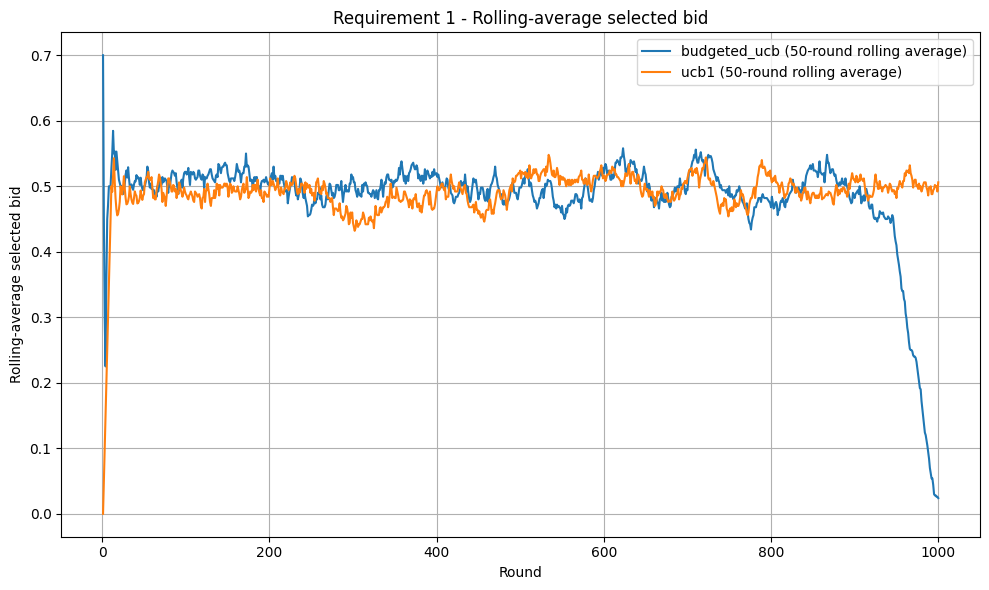

Plots directory: /Users/foadzahedilabaf/Projects/ola-project/results/plots
req1_cumulative_reward.png exists: True
req1_budget_left.png exists: True
req1_cumulative_cost.png exists: True
req1_selected_bid.png exists: True
req1_rolling_average_selected_bid.png exists: True


In [19]:
from ola.utils.plotting import generate_standard_req1_plots

plots_dir = PROJECT_ROOT / "results" / "plots"

# Generate the standard project plots.
generate_standard_req1_plots(
    dataframe=combined_results,
    plots_dir=plots_dir,
)

# Add an extra readability plot for selected bids.
# The raw selected-bid plot is correct, but very noisy because it shows every action.
rolling_window = 50

plt.figure(figsize=(10, 6))

for algorithm_name, group in combined_results.groupby("algorithm"):
    sorted_group = group.sort_values("round").copy()
    sorted_group["rolling_average_bid"] = (
        sorted_group["action"]
        .rolling(window=rolling_window, min_periods=1)
        .mean()
    )

    plt.plot(
        sorted_group["round"],
        sorted_group["rolling_average_bid"],
        label=f"{algorithm_name} ({rolling_window}-round rolling average)",
    )

plt.xlabel("Round")
plt.ylabel("Rolling-average selected bid")
plt.title("Requirement 1 - Rolling-average selected bid")
plt.legend()
plt.grid(True)
plt.tight_layout()

rolling_bid_plot_path = plots_dir / "req1_rolling_average_selected_bid.png"
plt.savefig(rolling_bid_plot_path, dpi=200)
plt.show()

expected_plot_files = [
    "req1_cumulative_reward.png",
    "req1_budget_left.png",
    "req1_cumulative_cost.png",
    "req1_selected_bid.png",
    "req1_rolling_average_selected_bid.png",
]

print("Plots directory:", plots_dir)

for filename in expected_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_cumulative_reward.png


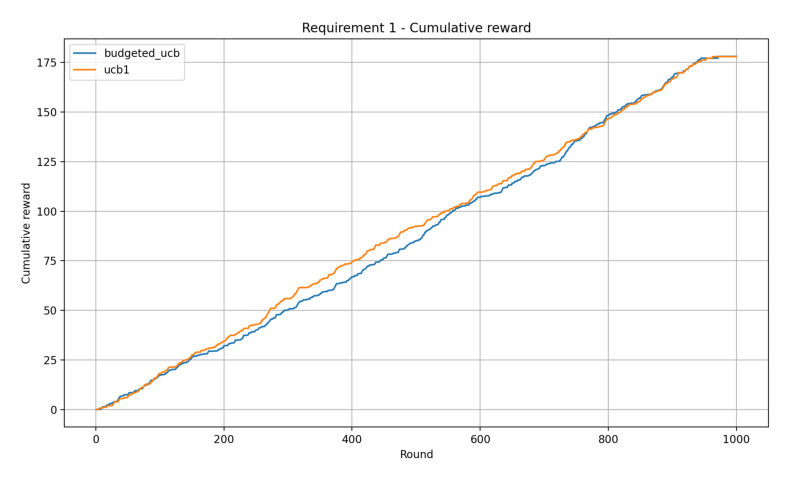

req1_budget_left.png


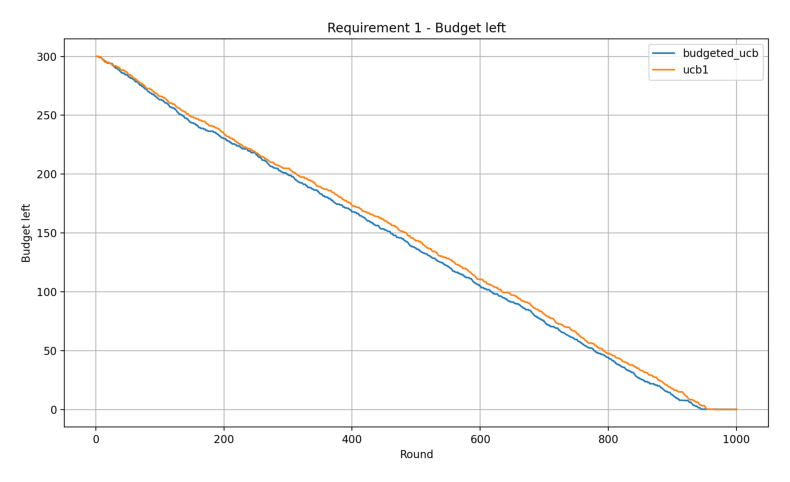

req1_cumulative_cost.png


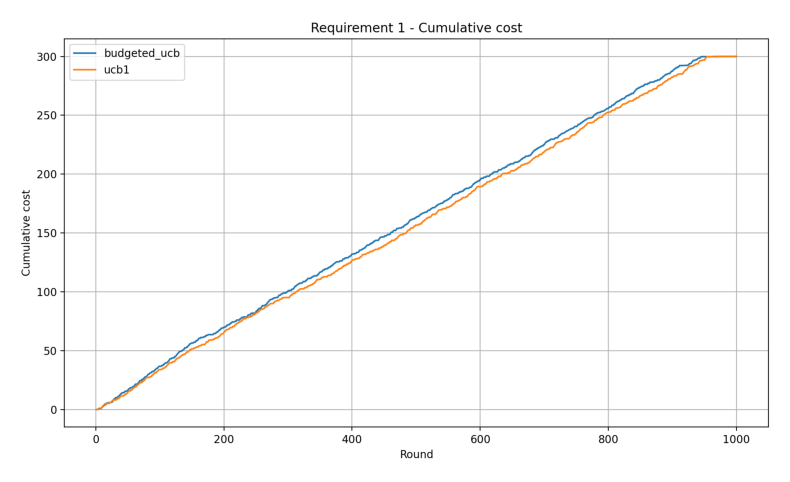

req1_selected_bid.png


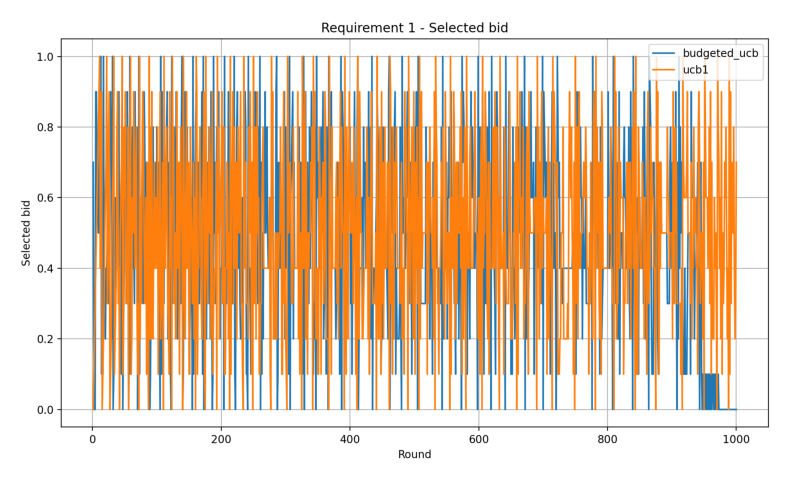

req1_rolling_average_selected_bid.png


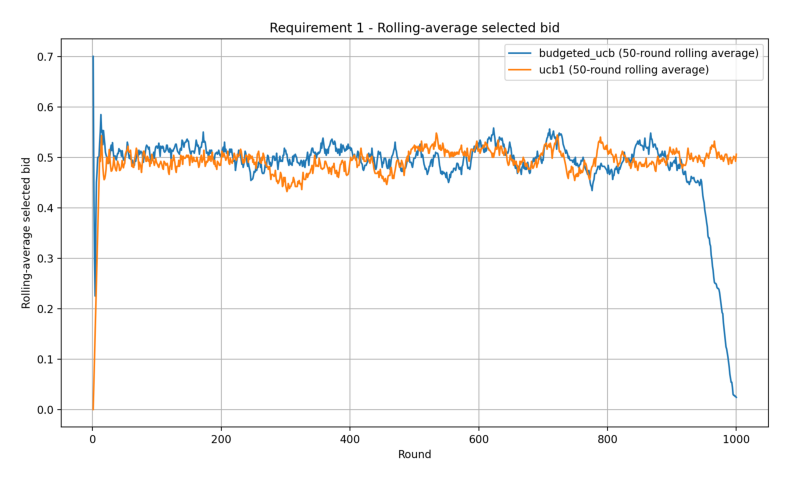

In [20]:
plot_paths = [
    plots_dir / "req1_cumulative_reward.png",
    plots_dir / "req1_budget_left.png",
    plots_dir / "req1_cumulative_cost.png",
    plots_dir / "req1_selected_bid.png",
    plots_dir / "req1_rolling_average_selected_bid.png",
]

for plot_path in plot_paths:
    print(plot_path.name)
    img = plt.imread(plot_path)

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## Plot interpretation

The cumulative reward plot shows that UCB1 and Budgeted UCB obtain very similar total rewards.  
This is expected in this configuration because the reward-maximizing bid is also feasible under the expected budget constraint.

The budget-left plot shows that both algorithms spend almost the entire budget by the end of the horizon.  
UCB1 reaches essentially zero remaining budget, while Budgeted UCB leaves a small positive amount.  
This is consistent with Budgeted UCB being slightly more conservative in its spending.

The cumulative-cost plot confirms the same behavior from the spending perspective.  
Both algorithms approach the budget limit, but Budgeted UCB remains slightly below it.

The raw selected-bid plot is noisy because it shows the exact bid selected at every round.  
This is normal for UCB-style algorithms, since they combine exploration and exploitation.

For readability, we also include a 50-round rolling-average selected-bid plot.  
This smoothed plot shows that both algorithms mostly bid around the reward-maximizing region, close to bid 0.5.  
Near the end, both algorithms reduce their effective bids because little budget remains, with Budgeted UCB remaining slightly more conservative.

## Additional robustness experiments: multiple seeds and tighter budget

The previous experiment uses one fixed random seed. This is useful for debugging and reproducibility, but the environment is stochastic. A stronger empirical evaluation repeats the experiment over multiple independent seeds.

In this section, we run both algorithms over several random seeds and report mean and standard deviation. We do this for two settings:

1. the official project configuration, with budget `B = 300`;
2. a tighter-budget stress test, with budget `B = 150`.

The stress test is not a replacement for the official configuration. It is an additional diagnostic experiment that makes the budget constraint more binding and helps us understand when budget-aware learning becomes more important.

In [21]:
MULTI_SEED_VALUES = list(range(30))


def run_req1_for_seed(seed, budget, label):
    """Run both Req 1 algorithms for one seed and one budget setting."""
    ucb1_benchmark_seed, budgeted_ucb_benchmark_seed = compute_req1_benchmarks(
        bids=bids,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
    )

    ucb1_seed = UCB1(actions=bids, horizon=horizon)
    ucb1_seed_rows = run_algorithm(
        algorithm_name="ucb1",
        learner=ucb1_seed,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        random_seed=seed,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        benchmark_reward_per_round=ucb1_benchmark_seed,
    )

    budgeted_ucb_seed = BudgetedUCB(
        actions=bids,
        horizon=horizon,
        initial_budget=budget,
    )
    budgeted_ucb_seed_rows = run_algorithm(
        algorithm_name="budgeted_ucb",
        learner=budgeted_ucb_seed,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        random_seed=seed,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        benchmark_reward_per_round=budgeted_ucb_benchmark_seed,
    )

    seed_df = pd.DataFrame(ucb1_seed_rows + budgeted_ucb_seed_rows)
    seed_df["seed"] = seed
    seed_df["budget_setting"] = label
    seed_df["initial_budget"] = budget

    return seed_df


multi_seed_frames = []

for seed in MULTI_SEED_VALUES:
    multi_seed_frames.append(
        run_req1_for_seed(
            seed=seed,
            budget=initial_budget,
            label="official_budget_B_300",
        )
    )
    multi_seed_frames.append(
        run_req1_for_seed(
            seed=seed,
            budget=150.0,
            label="tight_budget_B_150",
        )
    )

multi_seed_results = pd.concat(multi_seed_frames, ignore_index=True)

print("Multi-seed result shape:", multi_seed_results.shape)
print("Number of seeds:", multi_seed_results["seed"].nunique())
print("Budget settings:")
print(multi_seed_results["budget_setting"].value_counts())
print("\nAlgorithms:")
print(multi_seed_results["algorithm"].value_counts())

Multi-seed result shape: (103037, 19)
Number of seeds: 30
Budget settings:
budget_setting
official_budget_B_300    58584
tight_budget_B_150       44453
Name: count, dtype: int64

Algorithms:
algorithm
budgeted_ucb    60000
ucb1            43037
Name: count, dtype: int64


In [22]:
multi_seed_summary = (
    multi_seed_results
    .sort_values(["budget_setting", "seed", "algorithm", "round"])
    .groupby(["budget_setting", "initial_budget", "seed", "algorithm"])
    .agg(
        rounds_played=("round", "max"),
        total_reward=("cumulative_reward", "last"),
        total_cost=("cumulative_cost", "last"),
        final_budget_left=("budget_left", "last"),
        final_cumulative_regret=("cumulative_regret", "last"),
    )
    .reset_index()
)

multi_seed_aggregate_summary = (
    multi_seed_summary
    .groupby(["budget_setting", "initial_budget", "algorithm"])
    .agg(
        mean_rounds_played=("rounds_played", "mean"),
        std_rounds_played=("rounds_played", "std"),
        mean_total_reward=("total_reward", "mean"),
        std_total_reward=("total_reward", "std"),
        mean_total_cost=("total_cost", "mean"),
        std_total_cost=("total_cost", "std"),
        mean_final_budget_left=("final_budget_left", "mean"),
        std_final_budget_left=("final_budget_left", "std"),
        early_stop_rate=("rounds_played", lambda values: float((values < horizon).mean())),
    )
    .reset_index()
)

multi_seed_aggregate_summary

,budget_setting,initial_budget,algorithm,mean_rounds_played,std_rounds_played,mean_total_reward,std_total_reward,mean_total_cost,std_total_cost,mean_final_budget_left,std_final_budget_left,early_stop_rate
0,official_budget_B_300,300.0,budgeted_ucb,1000.000000,0.000000,169.850000,7.947880,299.816667,7.037257e-01,1.833333e-01,7.037257e-01,0.000000
1,official_budget_B_300,300.0,ucb1,952.800000,39.312541,171.506667,10.982335,299.960000,2.190890e-01,4.000000e-02,2.190890e-01,0.833333
2,tight_budget_B_150,150.0,budgeted_ucb,1000.000000,0.000000,80.590000,4.452148,149.910000,3.051286e-02,9.000000e-02,3.051286e-02,0.000000
3,tight_budget_B_150,150.0,ucb1,481.766667,100.764554,79.766667,6.600331,150.000000,6.921742e-14,2.516506e-16,1.378347e-15,0.966667


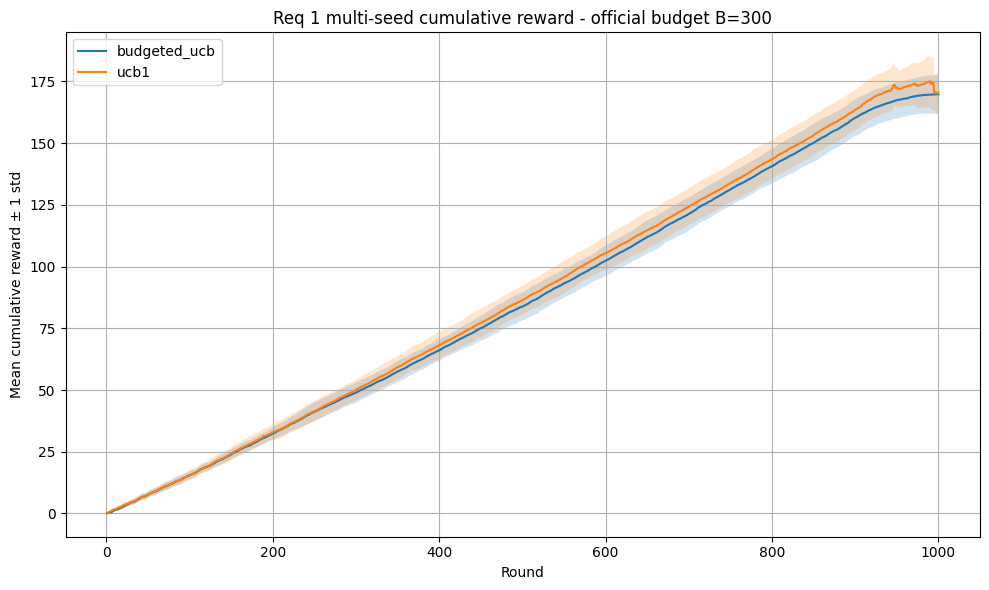

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_reward_official_budget.png
Plot exists: True


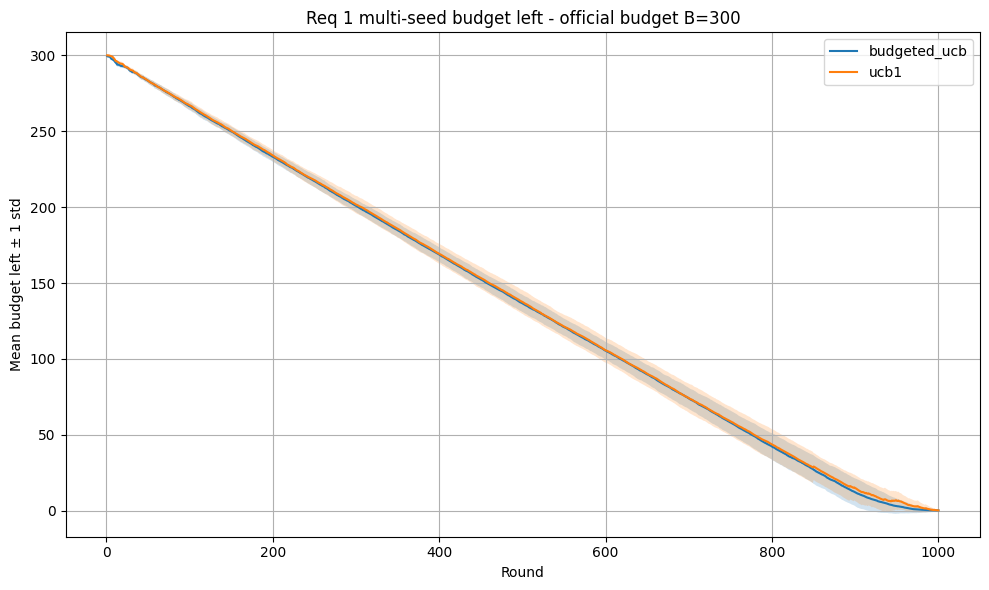

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_budget_left_official_budget.png
Plot exists: True


In [23]:
def plot_mean_with_std_band(dataframe, budget_setting, metric, ylabel, title, output_filename):
    """Plot mean trajectory with plus/minus one standard deviation over seeds."""
    setting_df = dataframe[dataframe["budget_setting"] == budget_setting]

    plt.figure(figsize=(10, 6))

    for algorithm_name, group in setting_df.groupby("algorithm"):
        pivot = group.pivot_table(
            index="round",
            columns="seed",
            values=metric,
            aggfunc="last",
        ).sort_index()

        mean_values = pivot.mean(axis=1)
        std_values = pivot.std(axis=1).fillna(0.0)

        rounds = mean_values.index.to_numpy(dtype=float)
        mean_array = mean_values.to_numpy(dtype=float)
        std_array = std_values.to_numpy(dtype=float)

        plt.plot(rounds, mean_array, label=algorithm_name)
        plt.fill_between(
            rounds,
            mean_array - std_array,
            mean_array + std_array,
            alpha=0.2,
        )

    plt.xlabel("Round")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    output_path = plots_dir / output_filename
    plt.savefig(output_path, dpi=200)
    plt.show()

    print("Saved plot to:", output_path)
    print("Plot exists:", output_path.exists())


plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="official_budget_B_300",
    metric="cumulative_reward",
    ylabel="Mean cumulative reward ± 1 std",
    title="Req 1 multi-seed cumulative reward - official budget B=300",
    output_filename="req1_multiseed_reward_official_budget.png",
)

plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="official_budget_B_300",
    metric="budget_left",
    ylabel="Mean budget left ± 1 std",
    title="Req 1 multi-seed budget left - official budget B=300",
    output_filename="req1_multiseed_budget_left_official_budget.png",
)

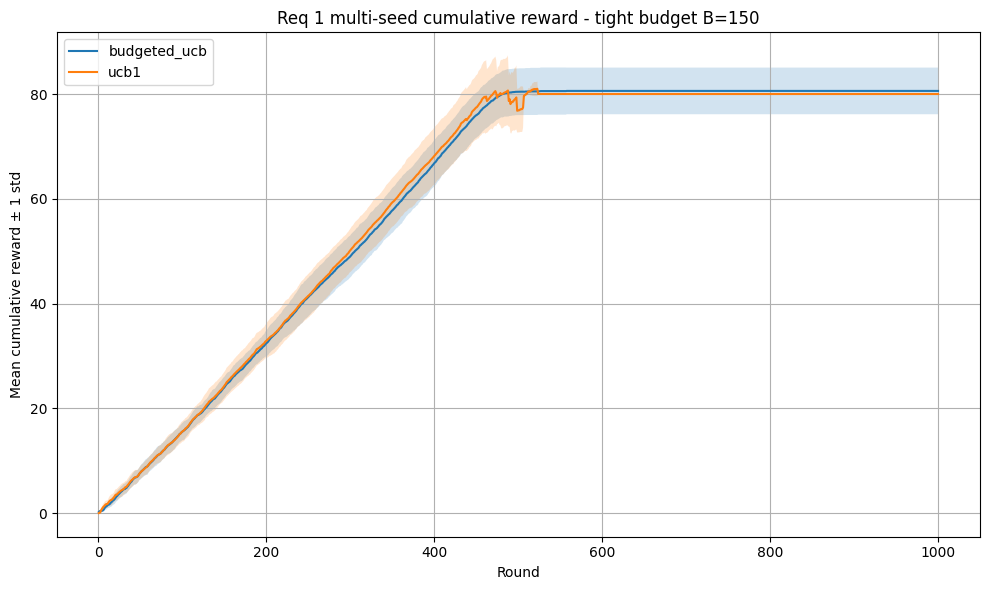

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_reward_tight_budget.png
Plot exists: True


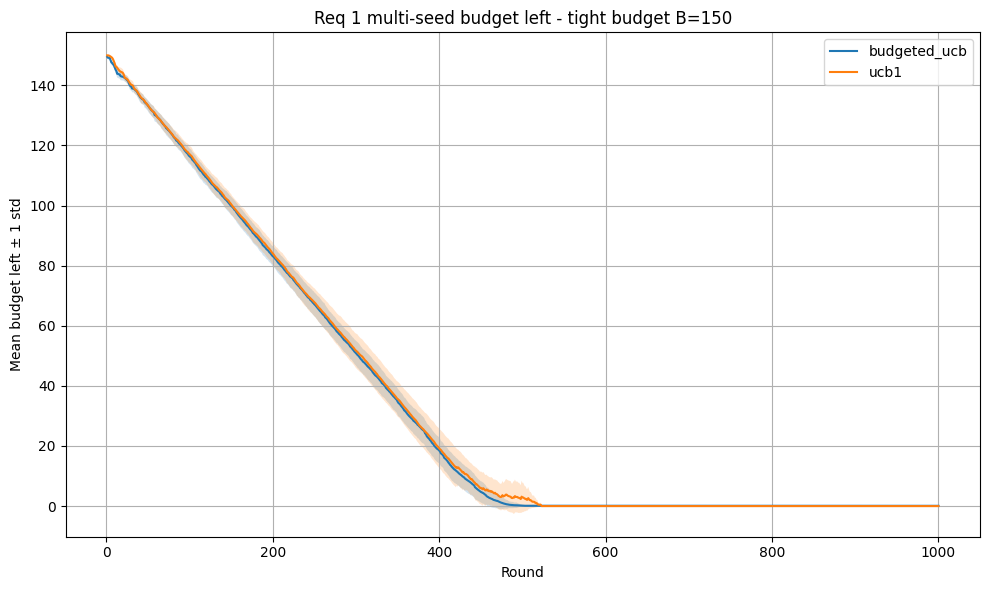

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_budget_left_tight_budget.png
Plot exists: True


In [24]:
plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="tight_budget_B_150",
    metric="cumulative_reward",
    ylabel="Mean cumulative reward ± 1 std",
    title="Req 1 multi-seed cumulative reward - tight budget B=150",
    output_filename="req1_multiseed_reward_tight_budget.png",
)

plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="tight_budget_B_150",
    metric="budget_left",
    ylabel="Mean budget left ± 1 std",
    title="Req 1 multi-seed budget left - tight budget B=150",
    output_filename="req1_multiseed_budget_left_tight_budget.png",
)

## Robustness experiment interpretation

The multi-seed experiment repeats the comparison over 30 independent stochastic environments. The solid lines show the average behavior, while the shaded regions represent plus/minus one standard deviation across seeds.

Under the official budget `B = 300`, the two algorithms remain close in cumulative reward. UCB1 obtains slightly higher average reward, but it stops early in many seeds because it spends the budget aggressively. Budgeted UCB is more conservative and reaches the full horizon in all seeds.

The tighter-budget stress test makes the budget constraint more binding. With `B = 150`, the per-round budget becomes:

$$
\rho = 150/1000 = 0.15.
$$

In this case, the reward-maximizing bid `0.5` is no longer feasible in expectation, because its expected cost is:

$$
\mathbb{E}[\text{cost at } b=0.5] = 0.5 \cdot 0.5 = 0.25 > 0.15.
$$

This explains why budget-aware learning becomes more important in the stress test. UCB1 often depletes the budget around the middle of the horizon, while Budgeted UCB keeps the interaction feasible until the final round.

These additional experiments do not replace the official Req 1 configuration. They strengthen the empirical analysis by showing average behavior, variability across seeds, and performance under a more restrictive budget.

In [26]:
extra_plot_files = [
    "req1_multiseed_reward_official_budget.png",
    "req1_multiseed_budget_left_official_budget.png",
    "req1_multiseed_reward_tight_budget.png",
    "req1_multiseed_budget_left_tight_budget.png",
]

for filename in extra_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_multiseed_reward_official_budget.png exists: True
req1_multiseed_budget_left_official_budget.png exists: True
req1_multiseed_reward_tight_budget.png exists: True
req1_multiseed_budget_left_tight_budget.png exists: True


## Requirement 1 completion checklist

Requirement 1 is complete for the current project configuration.

What this notebook verifies:

- The environment is a single-campaign stochastic first-price auction environment.
- The competing bid is sampled from a fixed uniform distribution.
- Rewards and costs follow the first-price auction rule: if the bid wins, reward is `value - bid` and cost is `bid`; otherwise both are zero.
- UCB1 learns over the finite bid set while ignoring the budget constraint.
- Budgeted UCB learns both rewards and costs and uses the budget-aware rule to control spending.
- The shared CSV output format is respected.
- The generated plots compare reward, budget usage, cumulative cost, raw selected bids, and smoothed selected bids.
- The robustness experiment repeats the comparison over 30 independent seeds.
- The robustness experiment reports mean and standard deviation across seeds.
- The tighter-budget stress test shows how the algorithms behave when the budget constraint is more binding.

Main empirical conclusion:

- In the official single-seed configuration, both UCB1 and Budgeted UCB reach the full horizon.
- UCB1 spends essentially the entire budget by the end of the horizon.
- Budgeted UCB reaches the full horizon while leaving a small positive remaining budget.
- The total rewards are close in the official configuration because the reward-maximizing bid is already feasible in expectation under the per-round budget.
- Across 30 seeds, UCB1 often stops early, especially under the tighter-budget stress test.
- Budgeted UCB reaches the full horizon in all multi-seed runs.
- The tighter-budget stress test makes the budget-aware behavior more visible.

Therefore, the main advantage of Budgeted UCB is budget feasibility and more reliable budget pacing, especially when the budget constraint becomes binding.